In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

df = pd.read_csv("../data/clean.csv")

print("Размер датасета:", df.shape)
print("Пропуски:", df.isna().sum().sum())
print("Дубликаты:", df.duplicated().sum())

display(df.head())


Размер датасета: (649, 33)
Пропуски: 0
Дубликаты: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
target = "G3"
X = df.drop(columns=["G3", "at_risk"], errors="ignore")
y = df[target]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

print("Числовых признаков:", len(num_cols))
print("Категориальных признаков:", len(cat_cols))
print("Целевая переменная:", target)


Числовых признаков: 15
Категориальных признаков: 17
Целевая переменная: G3


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)
print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)


Обучающая выборка: (486, 32)
Тестовая выборка: (163, 32)


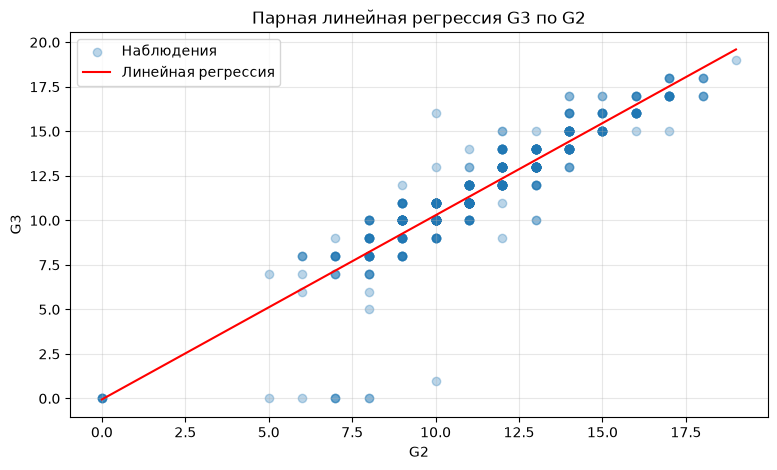

In [12]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/clean.csv")
train, _ = train_test_split(df, test_size=0.25, random_state=42)

lr = LinearRegression().fit(train[["G2"]], train["G3"])

x_line = np.linspace(train["G2"].min(), train["G2"].max(), 100)
y_line = lr.predict(pd.DataFrame({"G2": x_line}))

plt.figure(figsize=(9, 5))
plt.scatter(train["G2"], train["G3"], alpha=0.3, label="Наблюдения")
plt.plot(x_line, y_line, color="red", label="Линейная регрессия")

plt.xlabel("G2")
plt.ylabel("G3")
plt.title("Парная линейная регрессия G3 по G2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


CV R² полной модели: 0.837774

ТОП-15 коэффициентов Lasso:


,weight
pipeline-1__G2,2.451755
pipeline-1__G1,0.476178
pipeline-2__absences_0.0,-0.220154
pipeline-3__school_GP,0.079354
pipeline-1__failures,-0.047579
pipeline-1__Dalc,-0.045504
pipeline-1__health,-0.033784
pipeline-1__freetime,-0.030654
pipeline-1__studytime,0.025661
pipeline-1__famrel,-0.016716



Важность признаков через удаление:


,delta_cv_r2
G2,0.145489
G1,0.005589
absences,0.002027
studytime,0.000149
Mjob,0.000138
school,0.000132
famsup,0.000003
guardian,0.000000
activities,0.000000
nursery,0.000000


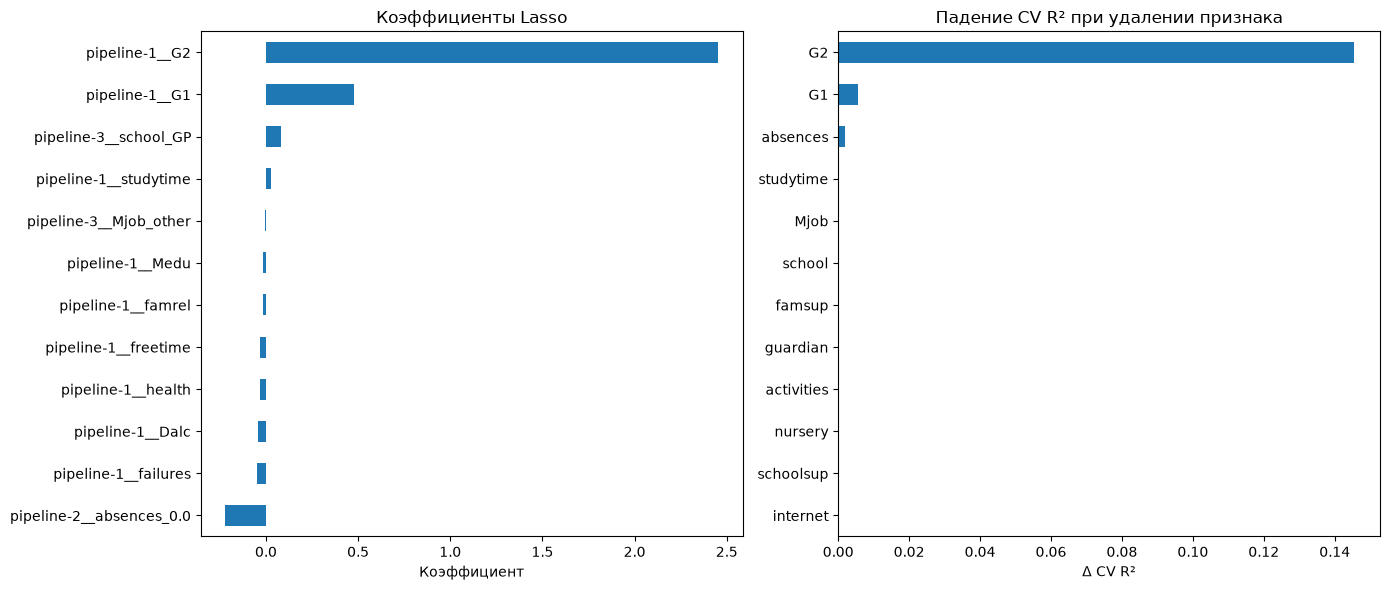


Корреляция G1 и G2: 0.8561
Важность G1: 0.005589
Важность G2: 0.145489

Асимметрия G3: -0.9913
Обычная Lasso CV R²: 0.837774
Lasso + log1p(G3) CV R²: 0.713375


In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import make_column_transformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (
    StandardScaler, OneHotEncoder, KBinsDiscretizer
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso

warnings.filterwarnings(
    "ignore",
    message="Bins whose width are too small.*"
)

# 1. Данные
df = pd.read_csv("../data/clean.csv")

X = df.drop(columns=["G3", "at_risk"], errors="ignore")
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

alpha = 0.05150678076168122

def make_lasso(cols):
    num = [
        c for c in cols
        if pd.api.types.is_numeric_dtype(X[c])
        and c != "absences"
    ]
    cat = [
        c for c in cols
        if not pd.api.types.is_numeric_dtype(X[c])
    ]
    transformers = []
    if num:
        transformers.append((
            make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler()
            ),
            num
        ))
    if "absences" in cols:
        transformers.append((
            make_pipeline(
                SimpleImputer(strategy="median"),
                KBinsDiscretizer(
                    n_bins=20,
                    encode="onehot",
                    strategy="quantile"
                )
            ),
            ["absences"]
        ))
    if cat:
        transformers.append((
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(handle_unknown="ignore")
            ),
            cat
        ))
    prep = make_column_transformer(*transformers)
    return make_pipeline(
        prep,
        Lasso(alpha=alpha, max_iter=50000)
    )
model = make_lasso(X.columns.tolist())
base_r2 = cross_val_score(
    model, X_train, y_train,
    cv=5, scoring="r2"
).mean()
model.fit(X_train, y_train)
print("CV R² полной модели:", round(base_r2, 6))
feature_names = model[0].get_feature_names_out()
weights = pd.Series(
    model[-1].coef_,
    index=feature_names
)

weights = weights.reindex(
    weights.abs().sort_values(ascending=False).index
)
print("\nТОП-15 коэффициентов Lasso:")
display(weights.head(15).round(6).to_frame("weight"))
importance = {}
for col in X.columns:
    remaining = [c for c in X.columns if c != col]

    reduced_model = make_lasso(remaining)

    reduced_r2 = cross_val_score(
        reduced_model,
        X_train[remaining],
        y_train,
        cv=5,
        scoring="r2"
    ).mean()

    importance[col] = base_r2 - reduced_r2

importance_df = (
    pd.Series(importance, name="delta_cv_r2")
    .sort_values(ascending=False)
)

print("\nВажность признаков через удаление:")
display(importance_df.round(6).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

weights.head(12).sort_values().plot.barh(
    ax=axes[0],
    title="Коэффициенты Lasso"
)
axes[0].set_xlabel("Коэффициент")

importance_df.head(12).sort_values().plot.barh(
    ax=axes[1],
    title="Падение CV R² при удалении признака"
)
axes[1].set_xlabel("Δ CV R²")

plt.tight_layout()
plt.show()

corr = X_train[["G1", "G2"]].corr().iloc[0, 1]

print("\nКорреляция G1 и G2:", round(corr, 4))
print("Важность G1:", round(importance_df["G1"], 6))
print("Важность G2:", round(importance_df["G2"], 6))
print("\nАсимметрия G3:", round(y_train.skew(), 4))

log_model = TransformedTargetRegressor(
    regressor=make_lasso(X.columns.tolist()),
    func=np.log1p,
    inverse_func=np.expm1
)

log_r2 = cross_val_score(
    log_model, X_train, y_train,
    cv=5, scoring="r2"
).mean()

print("Обычная Lasso CV R²:", round(base_r2, 6))
print("Lasso + log1p(G3) CV R²:", round(log_r2, 6))


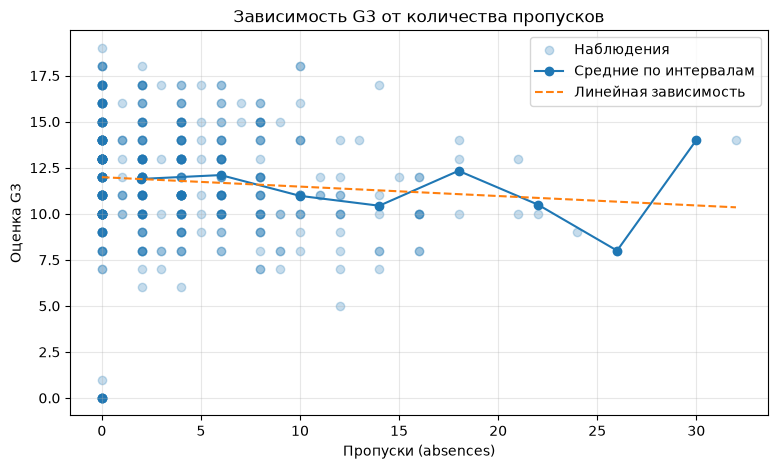

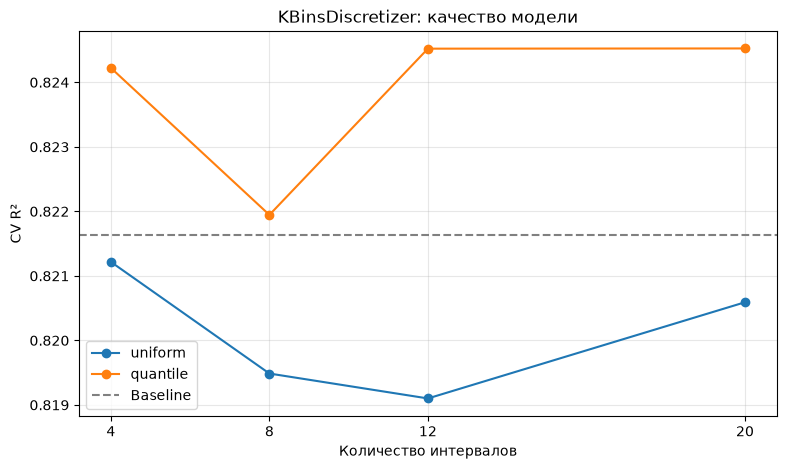

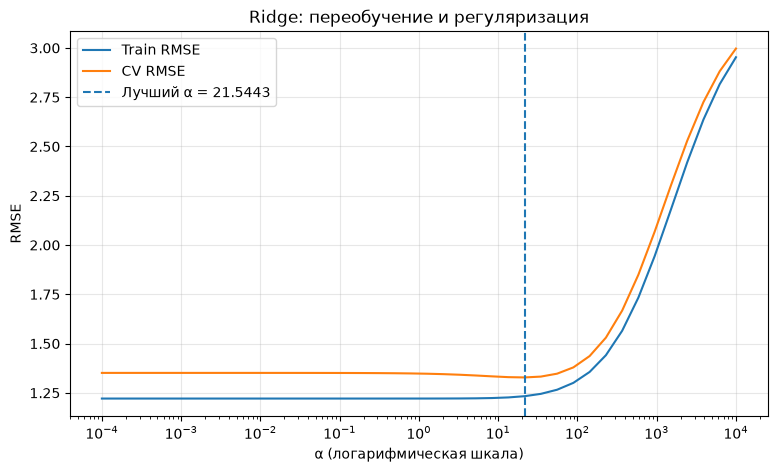

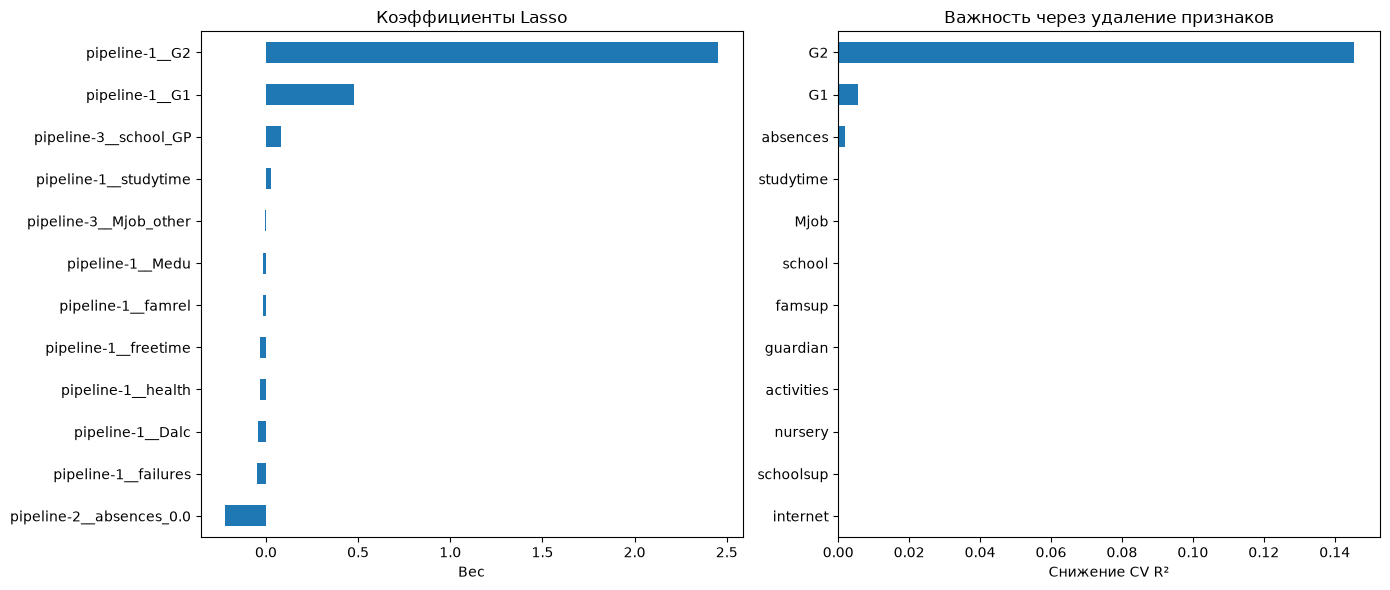


Сохранённые графики:
p3_absences.png
p3_bins.png
p4_ridge.png
p5_importance.png


In [ ]:

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, KBinsDiscretizer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore", message="Bins whose width are too small.*")

# Пути проекта
ROOT = Path.cwd()
if not (ROOT / "data" / "clean.csv").exists():
    ROOT = ROOT.parent

FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Данные
df = pd.read_csv(ROOT / "data" / "clean.csv")
X = df.drop(columns=["G3", "at_risk"], errors="ignore")
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()


def make_model(regressor, columns=None, n_bins=20, strategy="quantile"):
    if columns is None:
        columns = X.columns.tolist()

    nums = [c for c in columns if c in num_cols and c != "absences"]
    cats = [c for c in columns if c in cat_cols]

    transformers = []

    if nums:
        transformers.append((
            make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
            nums
        ))

    if "absences" in columns:
        transformers.append((
            make_pipeline(
                SimpleImputer(strategy="median"),
                KBinsDiscretizer(
                    n_bins=n_bins,
                    encode="onehot",
                    strategy=strategy
                )
            ),
            ["absences"]
        ))

    if cats:
        transformers.append((
            make_pipeline(
                SimpleImputer(strategy="most_frequent"),
                OneHotEncoder(handle_unknown="ignore")
            ),
            cats
        ))

    prep = make_column_transformer(*transformers)
    return make_pipeline(prep, regressor)


# ==========================================
# П3. График 1 — G3 от absences
# ==========================================

train = X_train.copy()
train["G3"] = y_train

groups = pd.cut(train["absences"], bins=8)
means = train.groupby(groups, observed=True)["G3"].mean()
midpoints = [interval.mid for interval in means.index]

coef = np.polyfit(train["absences"], train["G3"], 1)
x_line = np.linspace(train["absences"].min(), train["absences"].max(), 100)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(train["absences"], train["G3"], alpha=0.25, label="Наблюдения")
ax.plot(midpoints, means.values, "o-", label="Средние по интервалам")
ax.plot(x_line, np.polyval(coef, x_line), "--", label="Линейная зависимость")
ax.set(xlabel="Пропуски (absences)", ylabel="Оценка G3",
       title="Зависимость G3 от количества пропусков")
ax.legend()
ax.grid(alpha=0.3)

fig.savefig(FIG_DIR / "p3_absences.png", dpi=200, bbox_inches="tight")
plt.show()


# ==========================================
# П3. График 2 — CV R² от n_bins
# ==========================================

results = []

for strategy in ["uniform", "quantile"]:
    for n_bins in [4, 8, 12, 20]:
        model = make_model(
            LinearRegression(),
            n_bins=n_bins,
            strategy=strategy
        )

        cv_r2 = cross_val_score(
            model, X_train, y_train,
            cv=5, scoring="r2"
        ).mean()

        results.append({
            "strategy": strategy,
            "n_bins": n_bins,
            "cv_r2": cv_r2
        })

bins_df = pd.DataFrame(results)

fig, ax = plt.subplots(figsize=(9, 5))

for strategy in ["uniform", "quantile"]:
    sub = bins_df[bins_df["strategy"] == strategy]
    ax.plot(sub["n_bins"], sub["cv_r2"], "o-", label=strategy)

ax.axhline(0.821636, linestyle="--", color="gray", label="Baseline")
ax.set(xlabel="Количество интервалов", ylabel="CV R²",
       title="KBinsDiscretizer: качество модели")
ax.set_xticks([4, 8, 12, 20])
ax.legend()
ax.grid(alpha=0.3)

fig.savefig(FIG_DIR / "p3_bins.png", dpi=200, bbox_inches="tight")
plt.show()


# ==========================================
# П4. График 3 — Ridge RMSE от alpha
# ==========================================

ridge_results = []

for alpha in np.logspace(-4, 4, 40):
    model = make_model(Ridge(alpha=alpha))

    cv_rmse = -cross_val_score(
        model, X_train, y_train,
        cv=5, scoring="neg_root_mean_squared_error"
    ).mean()

    model.fit(X_train, y_train)

    train_rmse = np.sqrt(
        mean_squared_error(y_train, model.predict(X_train))
    )

    ridge_results.append({
        "alpha": alpha,
        "train_rmse": train_rmse,
        "cv_rmse": cv_rmse
    })

ridge_df = pd.DataFrame(ridge_results)
best_alpha = ridge_df.loc[ridge_df["cv_rmse"].idxmin(), "alpha"]

fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogx(ridge_df["alpha"], ridge_df["train_rmse"], label="Train RMSE")
ax.semilogx(ridge_df["alpha"], ridge_df["cv_rmse"], label="CV RMSE")
ax.axvline(best_alpha, linestyle="--", label=f"Лучший α = {best_alpha:.4f}")
ax.set(xlabel="α (логарифмическая шкала)", ylabel="RMSE",
       title="Ridge: переобучение и регуляризация")
ax.legend()
ax.grid(alpha=0.3)

fig.savefig(FIG_DIR / "p4_ridge.png", dpi=200, bbox_inches="tight")
plt.show()


# ==========================================
# П5. График 4 — Коэффициенты и важность
# ==========================================

alpha_lasso = 0.05150678076168122

model = make_model(Lasso(alpha=alpha_lasso, max_iter=50000))

base_r2 = cross_val_score(
    model, X_train, y_train,
    cv=5, scoring="r2"
).mean()

model.fit(X_train, y_train)

weights = pd.Series(
    model[-1].coef_,
    index=model[0].get_feature_names_out()
)

# Важность через удаление признаков
importance = {}

for col in X.columns:
    remaining = [c for c in X.columns if c != col]

    reduced = make_model(
        Lasso(alpha=alpha_lasso, max_iter=50000),
        columns=remaining
    )

    reduced_r2 = cross_val_score(
        reduced, X_train[remaining], y_train,
        cv=5, scoring="r2"
    ).mean()

    importance[col] = base_r2 - reduced_r2

importance = pd.Series(importance).sort_values(ascending=False)

top_weights = weights.reindex(
    weights.abs().sort_values(ascending=False).index
).head(12)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_weights.sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Коэффициенты Lasso")
axes[0].set_xlabel("Вес")

importance.head(12).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Важность через удаление признаков")
axes[1].set_xlabel("Снижение CV R²")

plt.tight_layout()
fig.savefig(FIG_DIR / "p5_importance.png", dpi=200, bbox_inches="tight")
plt.show()



Лучший alpha (LassoCV): 0.051507
Минимальный CV RMSE: 1.298702


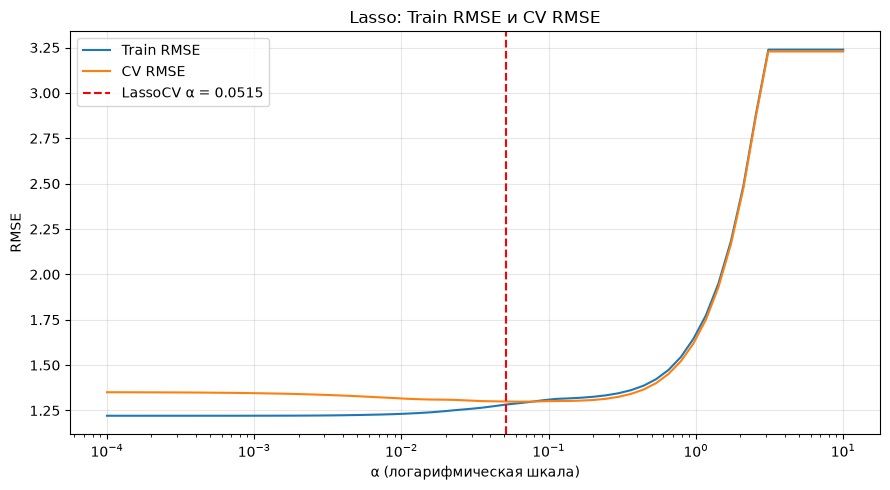

In [16]:

# ==========================================
# П4. График 4 — Lasso RMSE от alpha
# ==========================================

from sklearn.linear_model import Lasso, LassoCV

# 1. Проверяем значения alpha
alphas_lasso = np.logspace(-4, 1, 60)
lasso_results = []

for alpha in alphas_lasso:
    model = make_model(
        Lasso(alpha=alpha, max_iter=50000)
    )

    cv_rmse = -cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error"
    ).mean()

    model.fit(X_train, y_train)

    train_rmse = np.sqrt(
        mean_squared_error(
            y_train,
            model.predict(X_train)
        )
    )

    lasso_results.append({
        "alpha": alpha,
        "train_rmse": train_rmse,
        "cv_rmse": cv_rmse
    })

lasso_df = pd.DataFrame(lasso_results)

# 2. Подбор alpha через LassoCV
lasso_cv_model = make_model(
    LassoCV(
        alphas=alphas_lasso,
        cv=5,
        random_state=42,
        max_iter=50000
    )
)

lasso_cv_model.fit(X_train, y_train)
best_alpha_lasso = lasso_cv_model[-1].alpha_

print("Лучший alpha (LassoCV):", round(best_alpha_lasso, 6))
print("Минимальный CV RMSE:", round(lasso_df["cv_rmse"].min(), 6))

# 3. Строим график
fig, ax = plt.subplots(figsize=(9, 5))

ax.semilogx(
    lasso_df["alpha"],
    lasso_df["train_rmse"],
    label="Train RMSE"
)

ax.semilogx(
    lasso_df["alpha"],
    lasso_df["cv_rmse"],
    label="CV RMSE"
)

ax.axvline(
    best_alpha_lasso,
    linestyle="--",
    color="red",
    label=f"LassoCV α = {best_alpha_lasso:.4f}"
)

ax.set_xlabel("α (логарифмическая шкала)")
ax.set_ylabel("RMSE")
ax.set_title("Lasso: Train RMSE и CV RMSE")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

# 4. Сохраняем график
fig.savefig(
    FIG_DIR / "p4_lasso.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
